In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
mpc = pd.read_csv(r"C:\Users\User\Downloads\MPC.csv")
mpc['Ticker'] = 'MPC'

mtb = pd.read_csv(r"C:\Users\User\Downloads\MTB.csv")
mtb['Ticker'] = 'MTB'

sbux = pd.read_csv(r"C:\Users\User\Downloads\SBUX.csv")
sbux['Ticker'] = 'SBUX'

sjm = pd.read_csv(r"C:\Users\User\Downloads\SJM.csv")
sjm['Ticker'] = 'SJM'

df = pd.concat([mpc, mtb, sbux, sjm])
df['Date'] = pd.to_datetime(df['Date'])

df = df.set_index('Date').sort_index()

df


,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker
Date,,,,,,,,
2022-01-03,58.158,59.791,58.004,59.259,5855800,0.0,0.0,MPC
2022-01-03,134.160,136.632,133.704,136.296,1049800,0.0,0.0,MTB
2022-01-03,113.712,115.031,112.250,114.913,735200,0.0,0.0,SJM
2022-01-03,103.290,104.469,101.791,103.476,5475700,0.0,0.0,SBUX
2022-01-04,114.913,117.332,114.695,116.400,774400,0.0,0.0,SJM
...,...,...,...,...,...,...,...,...
2025-12-29,162.899,163.106,160.754,161.722,1847500,0.0,0.0,MPC
2025-12-30,201.363,201.363,199.247,199.453,496100,0.0,0.0,MTB
2025-12-30,162.701,162.919,160.951,161.940,1224000,0.0,0.0,MPC


In [ ]:
df['Difference'] = df['High'] - df['Low']
df[df['Difference']==0]['Ticker'].value_counts()
#there is no such ticker. this means - volatility is not high and it is steady.  

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Difference
Date,,,,,,,,,
2022-01-03,58.158,59.791,58.004,59.259,5855800,0.0,0.0,MPC,1.787
2022-01-03,134.160,136.632,133.704,136.296,1049800,0.0,0.0,MTB,2.928
2022-01-03,113.712,115.031,112.250,114.913,735200,0.0,0.0,SJM,2.781
2022-01-03,103.290,104.469,101.791,103.476,5475700,0.0,0.0,SBUX,2.678
2022-01-04,114.913,117.332,114.695,116.400,774400,0.0,0.0,SJM,2.637
...,...,...,...,...,...,...,...,...,...
2025-12-29,162.899,163.106,160.754,161.722,1847500,0.0,0.0,MPC,2.352
2025-12-30,201.363,201.363,199.247,199.453,496100,0.0,0.0,MTB,2.116
2025-12-30,162.701,162.919,160.951,161.940,1224000,0.0,0.0,MPC,1.968


In [26]:
g = df.groupby('Ticker')
pd.DataFrame({
    'highest_price': g['High'].max(),
    'lowest_price': g['Low'].min()
})

,highest_price,lowest_price
Ticker,,
MPC,210.577,58.004
MTB,213.332,97.624
SBUX,112.327,61.388
SJM,140.958,87.971


In [30]:
df['Log Returns'] = np.log(df['Close'] / df.groupby('Ticker')['Close'].shift(1))
df.groupby('Ticker')['Log Returns'].agg(['min', 'max', 'std', 'mean'])

,min,max,std,mean
Ticker,,,,
MPC,-0.139906,0.103059,0.020722,0.001004
MTB,-0.149529,0.114454,0.019564,0.000380
SBUX,-0.172894,0.219118,0.020582,-0.000217
SJM,-0.169512,0.055625,0.015375,-0.000194


In [ ]:
g = df.groupby('Ticker')
pd.DataFrame({
    'highest_gain_date': g['Log Returns'].idxmax(),
    'Lowest_gain_date': g['Log Returns'].idxmin()
})

,highest_gain_date,Lowest_gain-date
Ticker,,
MPC,2025-04-09,2025-04-03
MTB,2024-11-06,2022-10-19
SBUX,2024-08-13,2024-05-01
SJM,2022-06-07,2025-06-10


In [38]:
weekly_vol = df.groupby('Ticker')['Volume'].resample('W').median()
weekly_vol


Ticker  Date      
MPC     2022-01-09    7923800.0
        2022-01-16    6861800.0
        2022-01-23    7504650.0
        2022-01-30    9207900.0
        2022-02-06    7069300.0
                        ...    
SJM     2025-12-07    1598900.0
        2025-12-14    1265300.0
        2025-12-21    1561200.0
        2025-12-28    1317150.0
        2026-01-04    1291500.0
Name: Volume, Length: 836, dtype: float64

In [42]:
df.groupby('Ticker')['Log Returns'].sum().idxmin()
#SBUX did

'SBUX'

Ticker
MPC     Axes(0.125,0.2;0.775x0.68)
MTB     Axes(0.125,0.2;0.775x0.68)
SBUX    Axes(0.125,0.2;0.775x0.68)
SJM     Axes(0.125,0.2;0.775x0.68)
Name: Log Returns, dtype: object

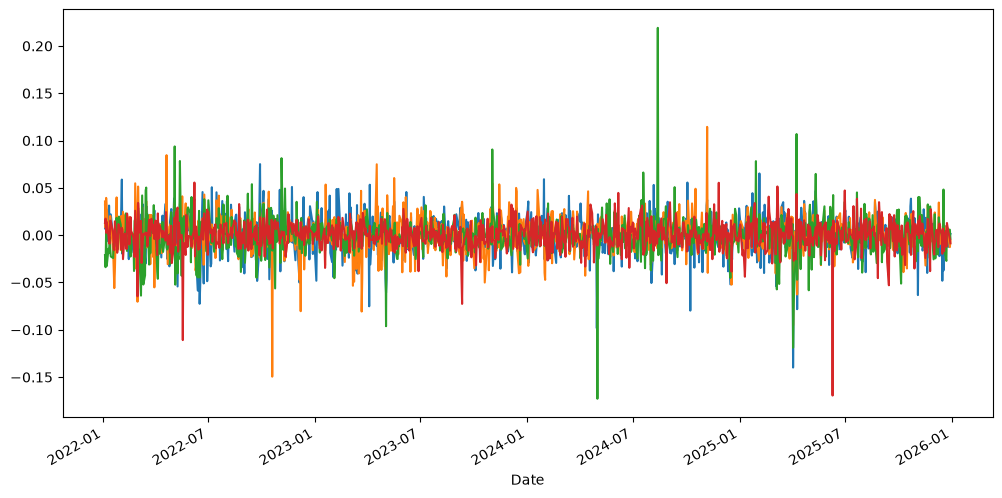

In [45]:
df.groupby('Ticker')['Log Returns'].plot(figsize=(12,6))

PART 2


In [50]:
nosub = pd.read_csv(r"C:\Users\User\Downloads\companies_no_subindustry.csv")
print(nosub.isna().sum())
print('There is ',45, 'missing included')

Symbol          0
Security        0
GICS_Sector     0
hq              0
included       45
Founded         0
dtype: int64
There is  45 missing included


In [ ]:
nosub.dropna(subset='included')

,Symbol,Security,GICS_Sector,hq,included,Founded
0,MMM,3M,Industrials,"Saint Paul, Minnesota",09.08.1976,1902
1,AOS,A. O. Smith,Industrials,"Milwaukee, Wisconsin",26.07.2017,1916
2,ABT,Abbott,Health Care,"North Chicago, Illinois",31.03.1964,1888
3,ABBV,AbbVie,Health Care,"North Chicago, Illinois",31.12.2012,2013 (1888)
4,ABMD,Abiomed,Health Care,"Danvers, Massachusetts",31.05.2018,1981
...,...,...,...,...,...,...
498,YUM,Yum! Brands,Consumer Discretionary,"Louisville, Kentucky",06.10.1997,1997
499,ZBRA,Zebra Technologies,Information Technology,"Lincolnshire, Illinois",23.12.2019,1969
500,ZBH,Zimmer Biomet,Health Care,"Warsaw, Indiana",07.08.2001,1927
501,ZION,Zions Bancorporation,Financials,"Salt Lake City, Utah",22.06.2001,1873


In [ ]:

oldest = nosub.loc[nosub['Founded'] == nosub['Founded'].min(), 'Security']
youngest = nosub.loc[nosub['Founded'] == nosub['Founded'].max(), 'Security']
print('Oldest: ', oldest)
print('Youngest: ', youngest)

Oldest:  71    BNY Mellon
Name: Security, dtype: str
Youngest:  481    Warner Bros. Discovery
Name: Security, dtype: str


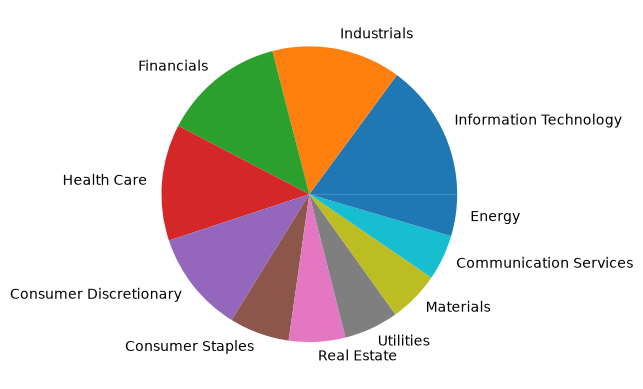

In [66]:
counts = nosub['GICS_Sector'].value_counts()
plt.pie(counts, labels = counts.index)

<Axes: xlabel='hq'>

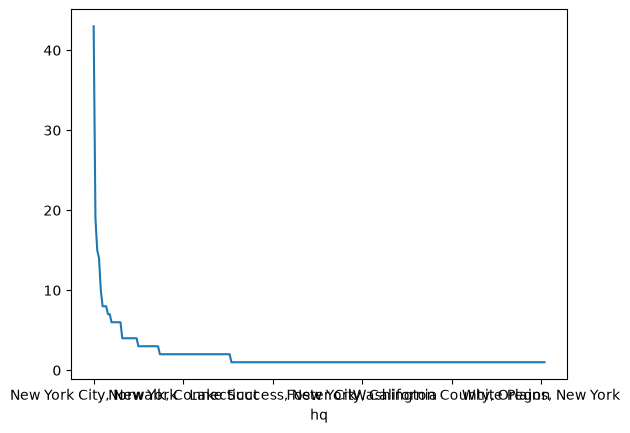

In [ ]:
nosub['hq'].value_counts().plot()

#from the graph it is visible that it has exponential distribution. 

In [73]:
sub = pd.read_csv(r"C:\Users\User\Downloads\companies_subindustry.csv")
merged = nosub.merge(sub, on='Symbol', how='left')
merged

,index,hq,Symbol,Security,GICS_Sector,included,Founded,subindustry
0,0,"Saint Paul, Minnesota",MMM,3M,Industrials,09.08.1976,1902,Industrial Conglomerates
1,1,"Milwaukee, Wisconsin",AOS,A. O. Smith,Industrials,26.07.2017,1916,Building Products
2,2,"North Chicago, Illinois",ABT,Abbott,Health Care,31.03.1964,1888,Health Care Equipment
3,3,"North Chicago, Illinois",ABBV,AbbVie,Health Care,31.12.2012,2013 (1888),Pharmaceuticals
4,4,"Danvers, Massachusetts",ABMD,Abiomed,Health Care,31.05.2018,1981,Health Care Equipment
...,...,...,...,...,...,...,...,...
498,498,"Louisville, Kentucky",YUM,Yum! Brands,Consumer Discretionary,06.10.1997,1997,Restaurants
499,499,"Lincolnshire, Illinois",ZBRA,Zebra Technologies,Information Technology,23.12.2019,1969,Electronic Equipment & Instruments
500,500,"Warsaw, Indiana",ZBH,Zimmer Biomet,Health Care,07.08.2001,1927,Health Care Equipment
501,501,"Salt Lake City, Utah",ZION,Zions Bancorporation,Financials,22.06.2001,1873,Regional Banks


<Axes: xlabel='subindustry'>

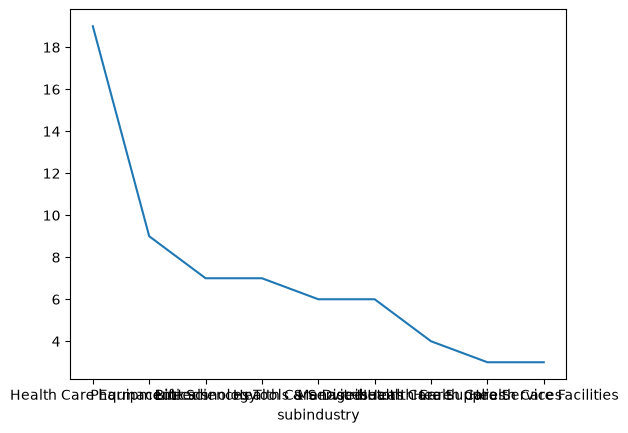

In [80]:
merged[merged['GICS_Sector']=='Health Care']['subindustry'].value_counts().plot()

In [ ]:
rng = np.random.default_rng(11)

normal = rng.normal(loc = 170, scale = 8, size = 200)
uniform = rng.uniform(low = 150, high=190, size = 300)
binom = rng.binomial(n=10, p=0.3, size=400)      
exp = rng.exponential(scale=2, size=500)



Text(0.5, 1.0, 'Uniform')

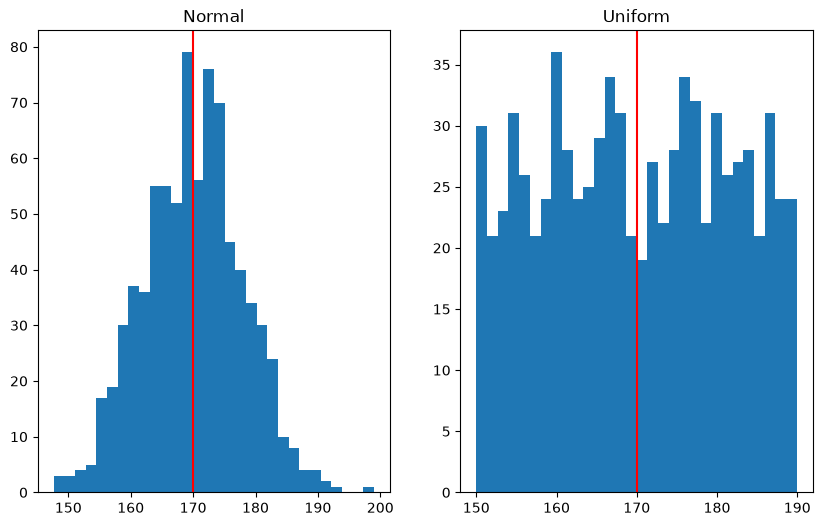

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(10,6))
axes[0].hist(normal, bins=30)
axes[0].axvline(normal.mean(), color='red')
axes[0].set_title('Normal')

axes[1].hist(uniform, bins=30)
axes[1].axvline(uniform.mean(), color='red')
axes[1].set_title('Uniform')


Text(0.5, 1.0, 'Exp')

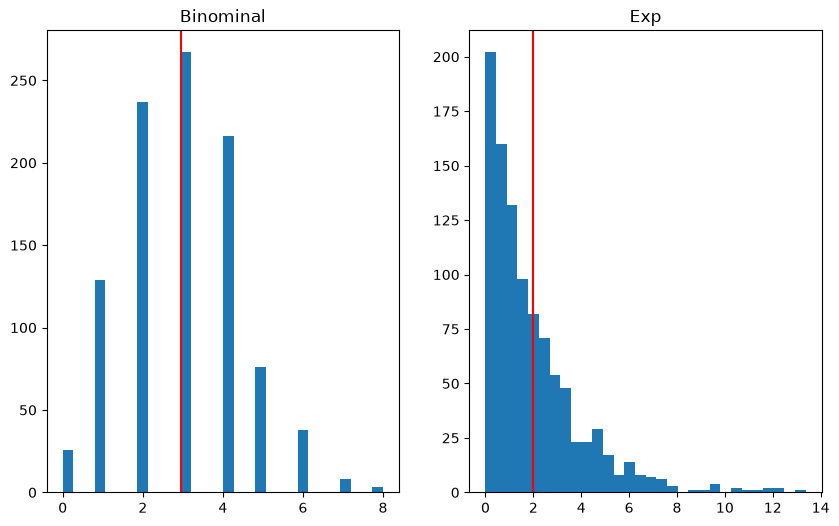

In [88]:
fig, axes = plt.subplots(1,2, figsize=(10,6))
axes[0].hist(binom, bins=30)
axes[0].axvline(binom.mean(), color='red')
axes[0].set_title('Binominal')

axes[1].hist(exp, bins=30)
axes[1].axvline(exp.mean(), color='red')
axes[1].set_title('Exp')

Text(0.5, 1.0, 'Uniform')

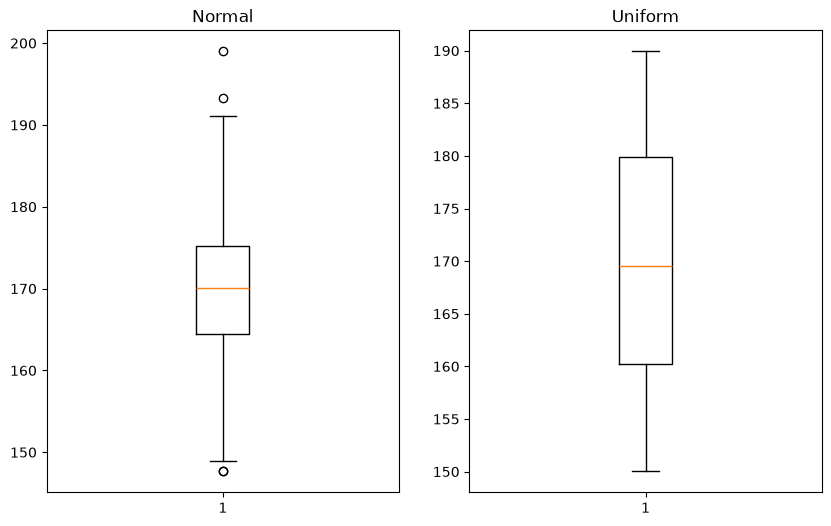

In [92]:
fig, axes = plt.subplots(1,2, figsize=(10,6))
axes[0].boxplot(normal)

axes[0].set_title('Normal')

axes[1].boxplot(uniform)

axes[1].set_title('Uniform')


Text(0.5, 1.0, 'EXP')

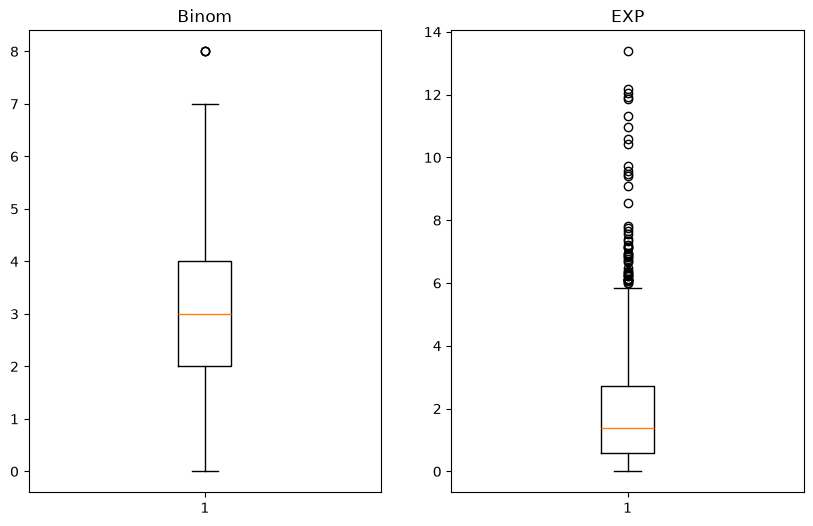

In [93]:
fig, axes = plt.subplots(1,2, figsize=(10,6))
axes[0].boxplot(binom)

axes[0].set_title('Binom')

axes[1].boxplot(exp)

axes[1].set_title('EXP')


BONUS PART

In [ ]:
divisors_list = []
for n in range(2, 21):
    divs = []
    for d in range(2, n):
        if n %d == 0:
            divs.append(d)
    divisors_list.append(divs)

print(divisors_list)

[[], [], [2], [], [2, 3], [], [2, 4], [3], [2, 5], [], [2, 3, 4, 6], [], [2, 7], [3, 5], [2, 4, 8], [], [2, 3, 6, 9], [], [2, 4, 5, 10]]


In [96]:
divisors_dict = dict(zip(range(2, 21), divisors_list))
divisors_dict

{2: [],
 3: [],
 4: [2],
 5: [],
 6: [2, 3],
 7: [],
 8: [2, 4],
 9: [3],
 10: [2, 5],
 11: [],
 12: [2, 3, 4, 6],
 13: [],
 14: [2, 7],
 15: [3, 5],
 16: [2, 4, 8],
 17: [],
 18: [2, 3, 6, 9],
 19: [],
 20: [2, 4, 5, 10]}